---
# DATA-445: Exam 2 - Part 3

## Instructions

- Exam 2 - Part 3 is worth **103** points.
- Please submit a **.ipynb** file to Blackboard.
- **Please strive for clarity and organization.**
- **AI usage**: You may use AI exclusively for **debugging**. Do not use AI to generate answers.
- **Due Date: November 20, 2026, by 12:50 PM.**
---

## Exercise 1

Consider the `df_train_part_3.csv` datafile. This dataset contains information about insurance policyholders (demographics, health, financial and policy characteristics) and the premium they pay. The goal is to build regression models to predict `Premium Amount`. Since this is a regression problem, model performance is measured with the **root mean squared error (RMSE)**; lower is better.

### (a) (3 points)
Read the datafile and create a data-frame called `df`. Remove any rows containing missing values.

In [11]:
import pandas as pd

df = pd.read_csv('df_train_part_3.csv')

df = df.dropna()

df.head()

,Age,Gender,Annual Income,Marital Status,Number of Dependents,Education Level,Occupation,Health Score,Location,Policy Type,Previous Claims,Vehicle Age,Credit Score,Insurance Duration,Premium Amount,Policy Start Date,Customer Feedback,Smoking Status,Exercise Frequency,Property Type
1,32.0,Male,112740.0,Married,0.0,Master's,Unemployed,19.720091,Urban,Premium,2.0,7,751.0,1,2319.0,2022-05-21 15:21:39.186212,Good,No,Monthly,Condo
5,38.0,Female,59862.0,Married,1.0,High School,Self-Employed,28.091608,Urban,Basic,0.0,19,582.0,7,366.0,2024-06-28 15:21:39.207847,Poor,No,Daily,Apartment
10,31.0,Male,43064.0,Single,3.0,High School,Self-Employed,31.159950,Suburban,Premium,0.0,8,486.0,6,316.0,2019-10-30 15:21:39.131192,Poor,Yes,Rarely,House
11,38.0,Female,3458.0,Married,1.0,Bachelor's,Employed,48.312153,Urban,Premium,0.0,19,507.0,3,463.0,2020-10-31 15:21:39.134960,Average,No,Weekly,Apartment
12,60.0,Female,42014.0,Single,0.0,Bachelor's,Unemployed,31.795101,Rural,Basic,0.0,12,500.0,8,473.0,2022-03-06 15:21:39.254678,Average,Yes,Rarely,Condo


### (b) (8 points)
There are ten object columns containing labels: `Gender`, `Marital Status`, `Education Level`, `Occupation`, `Location`, `Policy Type`, `Customer Feedback`, `Smoking Status`, `Exercise Frequency`, and `Property Type`. Convert those labels into numbers. *Hint*: you may consider using `OrdinalEncoder` from `sklearn.preprocessing`.

In addition, `Policy Start Date` is a timestamp stored as text. Convert it to datetime, create two numeric features, `Policy Start Year` and `Policy Start Month`, and drop the original column.

In [12]:
from sklearn.preprocessing import OrdinalEncoder

columns = ["Gender", "Marital Status", "Education Level", "Occupation", "Location",
            "Policy Type", "Customer Feedback", "Smoking Status",
            "Exercise Frequency", "Property Type"]
df[columns] = OrdinalEncoder().fit_transform(df[columns])

dates = pd.to_datetime(df['Policy Start Date'])
df['Policy Start Year'] = dates.dt.year
df['Policy Start Month'] = dates.dt.month
df = df.drop(columns=['Policy Start Date'])



### (c) (4 points)
Define `Premium Amount` as the target variable, and the other variables as the input features. Also, define the 5-fold cross-validation strategy.

In [13]:
from sklearn.model_selection import StratifiedKFold

X = df.drop(columns = ['Premium Amount'])

y = df['Premium Amount']

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### (d) (12 points)
Train and evaluate the `RandomForestRegressor` model (`n_estimators=1000`, `max_depth=10`, and `random_state=42`) over the 5-fold cross-validation strategy defined in part (c). Use the `RMSE` as measure of performance.

In [14]:
from sklearn.ensemble import RandomForestRegressor
import numpy as np
from sklearn.metrics import root_mean_squared_error

rf_md = RandomForestRegressor(n_estimators=1000,
                               max_depth=10,
                               random_state=42,
                               n_jobs=-1)

rmse_scores = []

for train_idx, val_idx in skf.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    rf_md.fit(X_train, y_train)
    preds = rf_md.predict(X_val)

    rmse = root_mean_squared_error(y_val, preds)
    rmse_scores.append(rmse)

rmse_scores = np.array(rmse_scores)
print("Fold RMSEs:", np.round(rmse_scores, 4))
print(f"Mean RMSE: {rmse_scores.mean():.4f})")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:784: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_of_target_y = type_of_target(y)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Fold RMSEs: [901.0057 982.4629 982.1903 959.0736 966.3932]
Mean RMSE: 958.2251)


### (e) (12 points)
Train and evaluate the `MLPRegressor` with two hidden layers: the first one with 8 neurons and `ReLU` as the activation function, the second one with 8 neurons and `ReLU` as the activation function. Also use `solver='adam'`, `max_iter=200` and `batch_size=256`, over the 5-fold cross validation strategy defined in part (c). Use the `RMSE` as measure of performance. Ensure to standardize the input features before you build the model.

In [15]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

mlp_md = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(8, 8),
                       activation='relu',
                       solver='adam',
                       max_iter=200,
                       batch_size=256,
                       random_state=42))

rmse_scores = []
for train_idx, val_idx in skf.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    mlp_md.fit(X_train, y_train)
    preds = mlp_md.predict(X_val)

    rmse = root_mean_squared_error(y_val, preds)
    rmse_scores.append(rmse)

rmse_scores = np.array(rmse_scores)
print("Fold RMSEs:", np.round(rmse_scores, 4))
print(f"Mean RMSE: {rmse_scores.mean():.4f}")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:784: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_of_target_y = type_of_target(y)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximu

Fold RMSEs: [ 941.7747 1020.6989 1040.5124  979.9969 1022.1461]
Mean RMSE: 1001.0258


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


### (f) (12 points)
Train and evaluate the `GradientBoostingRegressor` model (`n_estimators=1000`, `max_depth=8`, and `learning_rate=0.1`) over the 5-fold cross-validation strategy defined in part (c). Use the `RMSE` as measure of performance.

In [16]:
from sklearn.ensemble import GradientBoostingRegressor

gb_md = GradientBoostingRegressor(n_estimators=1000,
                                   max_depth=8,
                                   random_state=42,
                                   learning_rate=0.01)
 
rmse_scores = []

for train_idx, val_idx in skf.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    gb_md.fit(X_train, y_train)
    preds = gb_md.predict(X_val)

    rmse = root_mean_squared_error(y_val, preds)
    rmse_scores.append(rmse)

rmse_scores = np.array(rmse_scores)
print("Fold RMSEs:", np.round(rmse_scores, 4))
print(f"Mean RMSE: {rmse_scores.mean():.4f}")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:784: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_of_target_y = type_of_target(y)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


KeyboardInterrupt: 

### (g) (12 points)
Train and evaluate the `HistGradientBoostingRegressor` model (`max_iter=1000`, `max_depth=8`, and `learning_rate=0.1`) over the 5-fold cross-validation strategy defined in part (c). Use the `RMSE` as measure of performance.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

hgb_md = HistGradientBoostingRegressor(max_iter=1000,
                                        max_depth=8,
                                        learning_rate=0.01,
                                        random_state=42)

rmse_scores = []

for train_idx, val_idx in skf.split(X, y):
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    hgb_md.fit(X_train, y_train)
    preds = hgb_md.predict(X_val)

    rmse = root_mean_squared_error(y_val, preds)
    rmse_scores.append(rmse)

rmse_scores = np.array(rmse_scores)
print("Fold RMSEs:", np.round(rmse_scores, 4))
print(f"Mean RMSE: {rmse_scores.mean():.4f}")

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:784: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_of_target_y = type_of_target(y)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/model_selection/_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Fold RMSEs: [ 924.499  1013.0128 1002.5018 1003.9233 1025.1659]
Mean RMSE: 993.8206


### (h) (4 points)
Using the results from parts 1(d) to 1(g), what model would you use to predict `Premium Amount`?

Based on the results of RMSE i would chose the RandomForestRegressor to predict 'Premium Amount' it has the lowest overall error and its less prone to overfitting 

### (i) (18 points)
In this part you will explore **UMAP as a feature engineering approach**. Use the input features defined in part (c) (do **not** include `Premium Amount` when computing the embedding).

1. **(4 points)** Standardize the input features and fit a `UMAP` model (`n_components=2`, `n_neighbors=15`, `min_dist=0.1`, `random_state=42`). Make a scatter plot of the two-dimensional embedding, coloring each observation by `Premium Amount`. Is there any visible relationship between the embedding and the premium? (This step is exploratory only.)
2. **(10 points)** Create new features from a **5-dimensional** UMAP embedding (`n_components=5`, `n_neighbors=15`, `min_dist=0.1`, `random_state=42`) and add them to the original features. Build a `RandomForestRegressor` (same hyperparameters as in part 1(d)) using the original features plus the five UMAP components. Evaluate it over the same 5-fold cross-validation strategy defined in part (c), using the `RMSE`. To avoid data leakage, the scaler and `UMAP` must be fit **only on the training portion of each fold** (e.g., by using a `Pipeline` with a custom transformer, or by looping over the folds manually).
3. **(4 points)** Compare the mean out-of-sample `RMSE` of this model against the one obtained in part 1(d). Did adding the UMAP features improve performance? Briefly justify your answer.

**Step 1: two-dimensional UMAP embedding (exploratory)**

In [ ]:
# pip install umap-learn


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


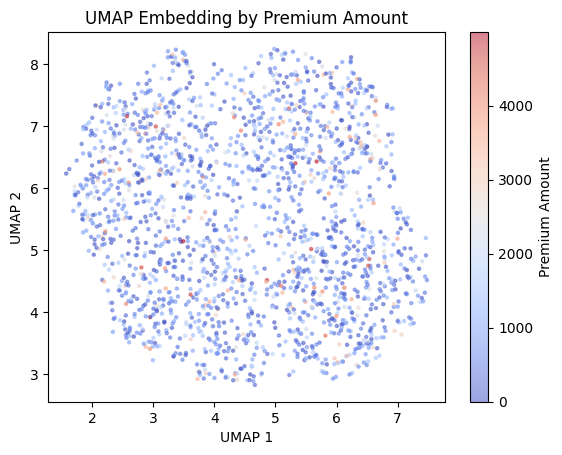

In [21]:
from umap import UMAP
import matplotlib.pyplot as plt

scaled = StandardScaler().fit_transform(X)
reducer = UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)

embed = reducer.fit_transform(scaled)

plt.scatter(embed[:, 0], embed[:, 1], c=y, cmap="coolwarm", s=5, alpha=0.5)
plt.colorbar(label="Premium Amount")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.title("UMAP Embedding by Premium Amount")
plt.show()


**Step 2: UMAP components as features (fit inside each fold)**

In [22]:
from sklearn.model_selection import KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = []

for train, val in kf.split(X, y):
  X_tr, X_va = X.iloc[train], X.iloc[val]
  y_tr, y_va = y.iloc[train], y.iloc[val]

  scaler = StandardScaler()
  umap_5 = UMAP(
      n_components=5, n_neighbors=15, min_dist=0.1, random_state=42
  )

  tr_u = umap_5.fit_transform(scaler.fit_transform(X_tr))
  va_u = umap_5.transform(scaler.transform(X_va))

  X_new = np.hstack([X_tr, tr_u])
  X_va_new = np.hstack([X_va, va_u])

  rf = RandomForestRegressor(
      n_estimators=1000, max_depth=10, random_state=42, n_jobs=-1
  )
  rf.fit(X_new, y_tr)
  scores.append(root_mean_squared_error(y_va, rf.predict(X_va_new)))

print("Fold RMSEs:", np.round(scores, 4))
print("Mean RMSE:", round(float(np.mean(scores)), 4))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the l

Fold RMSEs: [ 940.3877  988.9232 1040.548   954.4992  996.8151]
Mean RMSE: 984.2346


**Step 3: comparison with part 1(d)**

No there was not an improvement because the mean out of sample RMSE had an icncrease with UMAP

### (j) (18 points)
In this part you will explore **anomaly detection as a feature engineering approach**. Use the input features defined in part (c) (do **not** include `Premium Amount` when detecting anomalies). Use the `IsolationForest` detector (`n_estimators=300`, `contamination=0.05`, `random_state=42`).

1. **(4 points)** Fit the `IsolationForest` on the input features. Report how many observations are flagged as anomalies, and plot a histogram of the anomaly scores (use `-score_samples`, so that a *higher* value means *more anomalous*) marking the cutoff implied by `contamination=0.05`. Compare the mean and median `Premium Amount` of the flagged and non-flagged observations. (This step is exploratory only.)
2. **(10 points)** Create two new features from the detector: the anomaly score (`-score_samples`) and the binary anomaly flag (1 = anomaly, 0 = normal). Add them to the original features and build a `RandomForestRegressor` (same hyperparameters as in part 1(d)). Evaluate it over the same 5-fold cross-validation strategy defined in part (c), using the `RMSE`. To avoid data leakage, the `IsolationForest` must be fit **only on the training portion of each fold** (e.g., by using a `Pipeline` with a custom transformer, or by looping over the folds manually).
3. **(4 points)** Compare the mean out-of-sample `RMSE` of this model against the one obtained in part 1(d). Did adding the anomaly features improve performance? Briefly justify your answer.

**Step 1: anomalies found by the Isolation Forest (exploratory)**

Flagged anomalies: 93


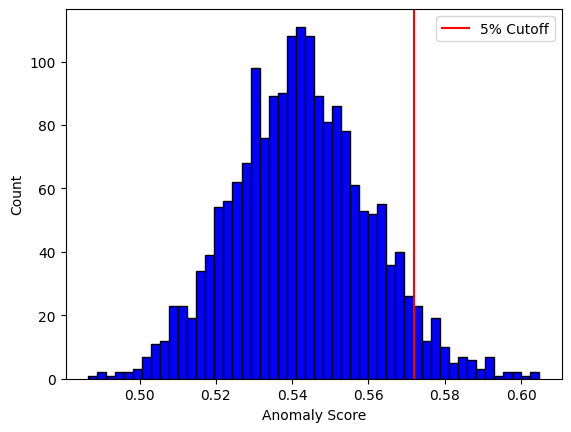

Flagged Mean: 1026.4516129032259 Median: 736.0
Normal Mean: 993.6749858196256 Median: 704.0


In [24]:
from sklearn.ensemble import IsolationForest


isfo = IsolationForest(n_estimators=300, contamination=0.05, random_state=42, n_jobs=-1)

flags = isfo.fit_predict(X)  
scores = -isfo.score_samples(X) 
cutoff = np.percentile(scores, 95)

print("Flagged anomalies:", np.sum(flags == -1))

plt.hist(scores, bins=50, color="blue", edgecolor="black")
plt.axvline(cutoff, color="red", label="5% Cutoff")
plt.xlabel("Anomaly Score")
plt.ylabel("Count")
plt.legend()
plt.show()

print("Flagged Mean:", y[flags == -1].mean(),"Median:",y[flags == -1].median(),)
print("Normal Mean:",y[flags == 1].mean(),"Median:",y[flags == 1].median(),)

**Step 2: anomaly score and flag as features (fit inside each fold)**

In [26]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scores = []

for tr, va in kf.split(X, y):
  X_tr, X_va = X.iloc[tr], X.iloc[va]
  y_tr, y_va = y.iloc[tr], y.iloc[va]

  isfo = IsolationForest(
      n_estimators=300, contamination=0.05, random_state=42, n_jobs=-1
  ).fit(X_tr)

  feats = np.column_stack(
      [X_tr, -isfo.score_samples(X_tr), (isfo.predict(X_tr) == -1).astype(int)]
  )
  va_feats = np.column_stack(
      [X_va, -isfo.score_samples(X_va), (isfo.predict(X_va) == -1).astype(int)]
  )

  rf = RandomForestRegressor(
      n_estimators=1000, max_depth=10, random_state=42, n_jobs=-1
  ).fit(feats, y_tr)
  scores.append(root_mean_squared_error(y_va, rf.predict(va_feats)))

print("Fold RMSEs:", np.round(scores, 4))
print("Mean RMSE:", round(float(np.mean(scores)), 4))

Fold RMSEs: [ 909.339   963.0129 1040.5157  904.9199  976.2156]
Mean RMSE: 958.8006


**Step 3: comparison with part 1(d)**

no adding the anomaly feature did not improve the performance. the anomaly features barley changed the models average error. Mean RMSE rose a little from 958.2251 to 958.8006 so they did not improve performance.